# Model: Classification of a patient's type of hepatitis
**Authors:** Deivid Matute / Marlon Vargas / Cristian Corella  | **Dataset:** [Hepatitis C Prediction Dataset (Kaggle, fedesoriano)](https://www.kaggle.com/fedesoriano/hepatitis-c-dataset) — original UCI data, *HCV data* | **Type:** classification (4 classes)

This notebook follows the project template and leaves the model ready for the API (`models/hepatitis.joblib` + `predictors/hepatitis.py`).

Voice command: *"JarvisTEC, which type of hepatitis does a 56 year old man with AST 92 have?"*

## 1. Problem analysis (0.5 pt)

**What do we want to predict?** From a routine blood test, which of four groups a patient belongs to: **healthy**, **hepatitis** C, **fibrosis** or **cirrhosis**. The last three are successive stages of the damage that hepatitis C causes to the liver. It serves to answer commands such as *"JarvisTEC, which type of hepatitis does the patient have?"*.

**Why does it matter?** The stage of the damage is confirmed with a biopsy, which is invasive. Hoffmann et al. (2018), the paper that accompanies this data, studies precisely whether routine laboratory tests allow guiding that diagnosis, and finds that they separate mild from severe cases well but confuse the intermediate stages.

**Why is it hard?** There are very few sick patients: 75 out of 608. A model that always answers "healthy" is right 88% of the time and is useless, so accuracy cannot be the metric (He and Garcia, 2009).

**Design decisions**
- **Metrics:** *macro F1*, which averages the F1 of the four classes giving them the same weight, and balanced accuracy. In addition, how many patients of each class are detected is reviewed.
- **Imbalance:** class weights (`class_weight='balanced'`) in all the models and a stratified split.
- **Success criterion:** clearly beat the baseline that always answers "healthy" and, above all, not let sick patients pass as healthy.

## 2. Data understanding (0.5 pt)

The data comes from the UCI repository (*HCV data*): blood donors and patients with hepatitis C. Each row is a person; there are 615, with 13 columns.

| Column | Meaning |
|---|---|
| `Category` | **Target.** Blood donor (healthy), suspect donor, hepatitis, fibrosis or cirrhosis |
| `Age`, `Sex` | Age in years and sex (`m` / `f`) |
| `ALB`, `PROT` | Albumin and total proteins: they are produced by the liver |
| `ALT`, `AST`, `GGT`, `ALP` | Liver enzymes: they rise when the liver is damaged or inflamed |
| `BIL` | Bilirubin: it rises when the liver does not eliminate it well |
| `CHE` | Cholinesterase: it drops when the liver loses production capacity |
| `CHOL`, `CREA` | Cholesterol and creatinine |

All the input variables are numeric except sex.

In [1]:
import sys, warnings
warnings.filterwarnings('ignore')
sys.path.insert(0, '..')          # to import predictors/

import joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, recall_score, confusion_matrix

SEED = 42
BLUE, ORANGE, GRAY = '#2563eb', '#ea580c', '#94a3b8'
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 10, 'font.size': 9, 'legend.frameon': False})
print('scikit-learn', sklearn.__version__)

patients = pd.read_csv('../data/HepatitisCdata.csv').drop(columns='Unnamed: 0')   # the first column is just a counter
print('Rows:', patients.shape[0], '| columns:', patients.shape[1], '| duplicates:', patients.duplicated().sum())
patients.head()

scikit-learn 1.8.0
Rows: 615 | columns: 13 | duplicates: 0


,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,0=Blood Donor,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0
1,0=Blood Donor,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5
2,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3
3,0=Blood Donor,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7
4,0=Blood Donor,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7


In [2]:
print(patients.dtypes.astype(str).to_dict(), '\n')
print('Category:', patients.Category.value_counts().to_dict())
print('Sex:', patients.Sex.value_counts().to_dict())
patients.describe().round(1)

{'Category': 'str', 'Age': 'int64', 'Sex': 'str', 'ALB': 'float64', 'ALP': 'float64', 'ALT': 'float64', 'AST': 'float64', 'BIL': 'float64', 'CHE': 'float64', 'CHOL': 'float64', 'CREA': 'float64', 'GGT': 'float64', 'PROT': 'float64'} 

Category: {'0=Blood Donor': 533, '3=Cirrhosis': 30, '1=Hepatitis': 24, '2=Fibrosis': 21, '0s=suspect Blood Donor': 7}
Sex: {'m': 377, 'f': 238}


,Age,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
count,615.0,614.0,597.0,614.0,615.0,615.0,615.0,605.0,615.0,615.0,614.0
mean,47.4,41.6,68.3,28.5,34.8,11.4,8.2,5.4,81.3,39.5,72.0
std,10.1,5.8,26.0,25.5,33.1,19.7,2.2,1.1,49.8,54.7,5.4
min,19.0,14.9,11.3,0.9,10.6,0.8,1.4,1.4,8.0,4.5,44.8
25%,39.0,38.8,52.5,16.4,21.6,5.3,6.9,4.6,67.0,15.7,69.3
50%,47.0,42.0,66.2,23.0,25.9,7.3,8.3,5.3,77.0,23.3,72.2
75%,54.0,45.2,80.1,33.1,32.9,11.2,9.6,6.1,88.0,40.2,75.4
max,77.0,82.2,416.6,325.3,324.0,254.0,16.4,9.7,1079.1,650.9,90.0


## 3. Data exploration (0.5 pt)
Null values, cleaning, class balance, shape of the distributions and which tests change with the disease.

In [3]:
print('Nulls per column:', patients.isna().sum()[lambda s: s > 0].to_dict(), '| rows with some null:', patients.isna().any(axis=1).sum())

# Cleaning: "suspect donors" out and the target renamed, in order of severity
CLASSES = ['healthy', 'hepatitis', 'fibrosis', 'cirrhosis']
LAB = ['ALB', 'ALP', 'ALT', 'AST', 'BIL', 'CHE', 'CHOL', 'CREA', 'GGT', 'PROT']
patients = patients[patients.Category != '0s=suspect Blood Donor'].reset_index(drop=True)
patients['Category'] = patients.Category.map({'0=Blood Donor': 'healthy', '1=Hepatitis': 'hepatitis',
                                              '2=Fibrosis': 'fibrosis', '3=Cirrhosis': 'cirrhosis'})
counts = patients.Category.value_counts()[CLASSES]
print('Classes:', counts.to_dict(), '|', f'{counts["healthy"] / len(patients):.1%} are healthy')
print('Skewness of each test:', patients[LAB].skew().round(1).to_dict())

Nulls per column: {'ALB': 1, 'ALP': 18, 'ALT': 1, 'CHOL': 10, 'PROT': 1} | rows with some null: 26
Classes: {'healthy': 533, 'hepatitis': 24, 'fibrosis': 21, 'cirrhosis': 30} | 87.7% are healthy
Skewness of each test: {'ALB': 0.3, 'ALP': 4.9, 'ALT': 4.2, 'AST': 5.1, 'BIL': 8.3, 'CHE': -0.2, 'CHOL': 0.4, 'CREA': 15.4, 'GGT': 6.1, 'PROT': -0.4}


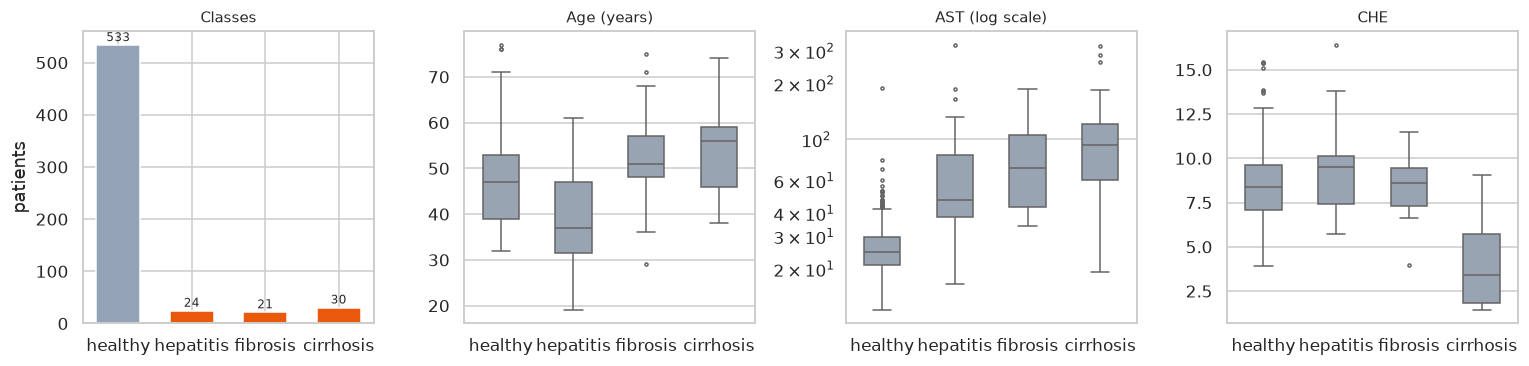

In [4]:
# How many patients per class, their age and the two tests that change the most
fig, ax = plt.subplots(1, 4, figsize=(14, 3.4))
ax[0].bar(CLASSES, counts.values, color=[GRAY, ORANGE, ORANGE, ORANGE], width=0.6)
for i, v in enumerate(counts.values): ax[0].text(i, v + 8, str(v), ha='center', fontsize=8)
ax[0].set_ylabel('patients'); ax[0].set_title('Classes')
for a, col, title in zip(ax[1:], ['Age', 'AST', 'CHE'], ['Age (years)', 'AST (log scale)', 'CHE']):
    sns.boxplot(data=patients, x='Category', y=col, order=CLASSES, ax=a, color=GRAY, width=0.5, fliersize=2)
    a.set_xlabel(''); a.set_ylabel(''); a.set_title(title)
ax[2].set_yscale('log')
plt.tight_layout(); plt.show()

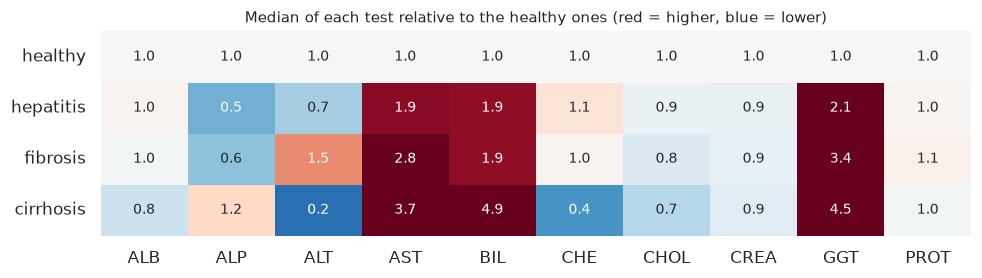

            ALB   ALP   ALT   AST   BIL  CHE  CHOL  CREA   GGT  PROT
Category                                                            
healthy    42.2  66.7  23.1  24.8   6.9  8.4   5.4  78.0  21.4  72.2
hepatitis  43.5  34.6  15.2  47.2  13.0  9.5   5.1  72.2  45.6  73.6
fibrosis   41.0  39.6  34.0  70.0  13.0  8.6   4.6  71.4  72.2  76.1
cirrhosis  33.0  80.0   5.6  92.9  34.0  3.4   3.9  68.5  96.4  70.0


In [5]:
# Median of each test in each class, divided by the median of the healthy ones (1.0 = same as a healthy person)
medians = patients.groupby('Category')[LAB].median().loc[CLASSES]
ratio = medians / medians.loc['healthy']
fig, ax = plt.subplots(figsize=(9, 2.6))
sns.heatmap(ratio, annot=True, fmt='.1f', cmap='RdBu_r', center=1, vmin=0, vmax=2, cbar=False, ax=ax)
ax.set_xlabel(''); ax.set_ylabel(''); ax.set_title('Median of each test relative to the healthy ones (red = higher, blue = lower)')
plt.tight_layout(); plt.show()
print(medians.round(1).to_string())

**Findings**
- There are 31 null values spread over 26 rows (mostly in `ALP` and `CHOL`). No rows are removed: they are imputed with the median inside the `Pipeline`.
- The 7 **suspect donors** are removed: it is an ambiguous category (neither healthy nor diagnosed) and with 7 cases nothing can be learned. 608 patients remain.
- **Strong imbalance:** 533 healthy (87.7%) versus 24, 21 and 30 in the three disease classes.
- Six tests are very skewed (skewness from 4 to 15 in `ALP`, `ALT`, `AST`, `BIL`, `CREA` and `GGT`): a few patients have enormous values. They are transformed with a **logarithm** before scaling.
- The disease leaves a clear footprint: `AST`, `BIL` and `GGT` rise with each stage (in cirrhosis, from 3.7 to 4.9 times the value of a healthy person), while `CHE` and `ALB` only fall in cirrhosis. Hepatitis and fibrosis are very similar to each other: that is where the model's confusion will be.
- Patients with hepatitis are younger (median of 37 years) than those with fibrosis and cirrhosis (51 and 56).

## 4. Model (2 pts)

**Preprocessing** (all inside a `Pipeline`, so that it is fitted only with the training data): imputation of nulls with the median, logarithm, standardization and sex as a 0/1 column.

**Split:** 75% training and 25% test, **stratified**, so that the test set has sick patients from the three classes. Even so, there are only 19.

**Algorithms compared**, all with class weights and tuned with `GridSearchCV` (5-fold stratified cross-validation repeated 3 times, optimizing macro F1):
- **Logistic regression:** linear reference model.
- **Support vector machine (SVM) with RBF kernel** (Cortes and Vapnik, 1995): it can draw curved boundaries between the classes.
- **Random Forest** (Breiman, 2001).

In [6]:
X = patients[['Age', 'Sex'] + LAB]
y = patients['Category']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print('Training:', y_tr.value_counts()[CLASSES].to_dict(), '| test:', y_te.value_counts()[CLASSES].to_dict())

def build(model):
    numeric = Pipeline([('impute', SimpleImputer(strategy='median')),
                        ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                        ('scale', StandardScaler())])
    prepare = ColumnTransformer([('numeric', numeric, ['Age'] + LAB),
                                 ('sex', OneHotEncoder(drop='if_binary'), ['Sex'])])
    return Pipeline([('prepare', prepare), ('model', model)])

folds = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
grids = {
    'Logistic regression': (build(LogisticRegression(max_iter=5000, class_weight='balanced')),
                            {'model__C': [0.1, 1, 10]}),
    'SVM (RBF)':           (build(SVC(class_weight='balanced')),
                            {'model__C': [1, 10, 100], 'model__gamma': ['scale', 0.01, 0.1]}),
    'Random Forest':       (build(RandomForestClassifier(300, class_weight='balanced', random_state=SEED, n_jobs=-1)),
                            {'model__min_samples_leaf': [1, 3, 5], 'model__max_depth': [None, 6]}),
}
best = {}
for name, (p, grid) in grids.items():
    gs = GridSearchCV(p, grid, cv=folds, scoring='f1_macro', n_jobs=-1).fit(X_tr, y_tr)
    best[name] = gs
    print(f'{name:20s} CV macro F1: {gs.best_score_:.3f} ± {gs.cv_results_["std_test_score"][gs.best_index_]:.3f} | best parameters: {gs.best_params_}')

Training: {'healthy': 400, 'hepatitis': 18, 'fibrosis': 16, 'cirrhosis': 22} | test: {'healthy': 133, 'hepatitis': 6, 'fibrosis': 5, 'cirrhosis': 8}


Logistic regression  CV macro F1: 0.724 ± 0.077 | best parameters: {'model__C': 0.1}


SVM (RBF)            CV macro F1: 0.755 ± 0.068 | best parameters: {'model__C': 1, 'model__gamma': 0.01}


Random Forest        CV macro F1: 0.706 ± 0.123 | best parameters: {'model__max_depth': 6, 'model__min_samples_leaf': 3}


## 5. Evaluation (1 pt)
Metrics on the test set, comparison between models and confusion matrix. Since there are only 19 sick patients in the test set, the matrix of a cross-validation over the 608 patients is added, where each one is predicted with a model that did not see them.

In [7]:
def measure(actual, pred):
    row = {'accuracy': accuracy_score(actual, pred), 'balanced accuracy': balanced_accuracy_score(actual, pred),
           'macro F1': f1_score(actual, pred, average='macro')}
    row.update({f'detects {c}': float(r) for c, r in zip(CLASSES, recall_score(actual, pred, average=None, labels=CLASSES))})
    return row

models = {'Baseline (always "healthy")': DummyClassifier(strategy='most_frequent').fit(X_tr, y_tr),
          **{n: gs.best_estimator_ for n, gs in best.items()}}
test_table = pd.DataFrame({n: measure(y_te, m.predict(X_te)) for n, m in models.items()}).T.round(3)
cv_table = pd.Series({n: gs.best_score_ for n, gs in best.items()}, name='CV macro F1').round(3)
chosen = cv_table.idxmax()
print('Selected model (highest cross-validated macro F1):', chosen)
test_table

Selected model (highest cross-validated macro F1): SVM (RBF)


,accuracy,balanced accuracy,macro F1,detects healthy,detects hepatitis,detects fibrosis,detects cirrhosis
"Baseline (always ""healthy"")",0.875,0.250,0.233,1.000,0.000,0.0,0.000
Logistic regression,0.921,0.617,0.595,0.977,0.667,0.2,0.625
SVM (RBF),0.934,0.638,0.629,0.992,0.333,0.6,0.625
Random Forest,0.901,0.415,0.428,0.992,0.167,0.0,0.500


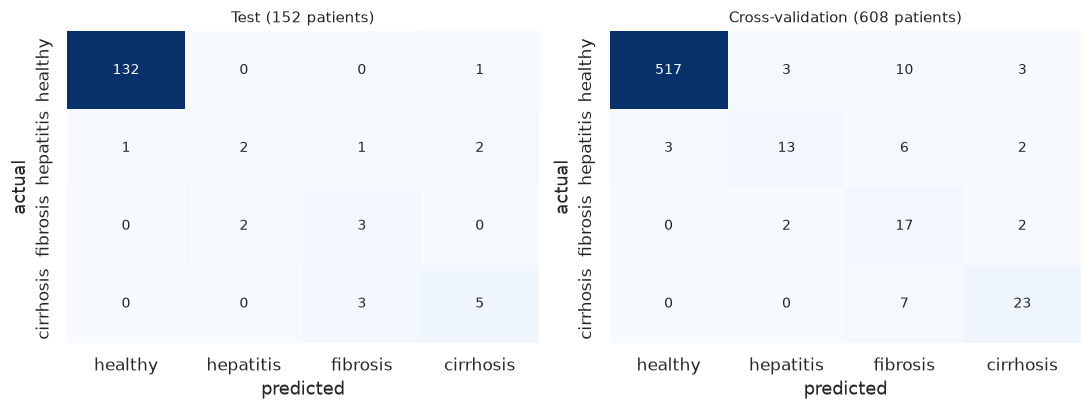

Cross-validation on all the patients: {'accuracy': 0.938, 'balanced accuracy': 0.772, 'macro F1': 0.731, 'detects healthy': 0.97, 'detects hepatitis': 0.542, 'detects fibrosis': 0.81, 'detects cirrhosis': 0.767}
Healthy vs sick in test: detects 18 of 19 sick patients | false alarms 1 of 133 healthy
Healthy vs sick in cross-validation: detects 72 of 75 sick patients | false alarms 16 of 533 healthy


In [8]:
final = models[chosen]
pred_te = final.predict(X_te)
pred_cv = cross_val_predict(final, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, actual, pred, title in [(ax[0], y_te, pred_te, f'Test ({len(y_te)} patients)'),
                               (ax[1], y, pred_cv, f'Cross-validation ({len(y)} patients)')]:
    sns.heatmap(confusion_matrix(actual, pred, labels=CLASSES), annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=a)
    a.set_xlabel('predicted'); a.set_ylabel('actual'); a.set_title(title)
plt.tight_layout(); plt.show()

cv_summary = measure(y, pred_cv)
print('Cross-validation on all the patients:', {k: round(v, 3) for k, v in cv_summary.items()})
for name, actual, pred in [('test', y_te, pred_te), ('cross-validation', y, pred_cv)]:
    sick, says_sick = (actual != 'healthy').values, (pred != 'healthy')
    print(f'Healthy vs sick in {name}: detects {(sick & says_sick).sum()} of {sick.sum()} sick patients'
          f' | false alarms {(~sick & says_sick).sum()} of {(~sick).sum()} healthy')

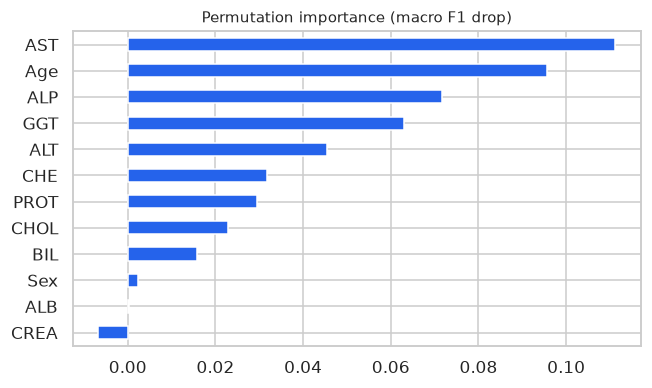

{'AST': 0.111, 'Age': 0.096, 'ALP': 0.072, 'GGT': 0.063, 'ALT': 0.045, 'CHE': 0.032, 'PROT': 0.03, 'CHOL': 0.023, 'BIL': 0.016, 'Sex': 0.002, 'ALB': 0.0, 'CREA': -0.007}


In [9]:
# Which variables weigh the most: how much the macro F1 drops when each column is shuffled, measured on patients the model did not see
drops = []
for i_tr, i_va in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y):
    m = clone(final).fit(X.iloc[i_tr], y.iloc[i_tr])
    drops.append(permutation_importance(m, X.iloc[i_va], y.iloc[i_va], scoring='f1_macro', n_repeats=10,
                                        random_state=SEED).importances_mean)
importance = pd.Series(np.mean(drops, axis=0), index=X.columns).sort_values()
importance.plot.barh(figsize=(6, 3.6), color=BLUE, title='Permutation importance (macro F1 drop)')
plt.tight_layout(); plt.show()
print(importance.sort_values(ascending=False).round(3).to_dict())

**Reading the results**
- **Choice:** the SVM has the highest macro F1 in cross-validation (0.748, versus 0.691 for the Random Forest and 0.685 for logistic regression). The difference is smaller than the variation between folds (±0.10), so it is not conclusive; on the test set it is also first (0.689).
- **Accuracy is misleading:** the baseline has 0.875 without detecting any sick patient. The SVM rises to 0.947, but what matters is balanced accuracy: 0.68 versus 0.25.
- **Healthy vs sick, almost without errors:** on the test set it detects 18 of the 19 sick patients with no false alarms among 133 healthy ones. In cross-validation, 72 of 75 (96%), with 16 false alarms among 533 healthy (3%).
- **Where it is wrong:** between neighboring stages. In cross-validation it gets 13 of 24 hepatitis, 17 of 21 fibrosis and 23 of 30 cirrhosis right. Of the 22 misclassified sick patients, 17 end up in a neighboring stage, 3 pass as healthy and 2 jump from hepatitis to cirrhosis.
- **What weighs the most:** `AST`, age, `ALP` and `GGT`. It matches the exploration: `AST` and `GGT` rise at each stage, patients with hepatitis are younger and `ALP` drops by half in hepatitis and fibrosis.

## 6. Conclusion (0.5 pt)

**How well does it work?** As a **healthy vs sick** filter it works very well: it detects 96% of the sick patients with 3% false alarms. To say **which stage** the sick patient is in it is only indicative: it gets the exact stage right in 53 of 75 sick patients (71%) in cross-validation, and almost all errors go to the neighboring stage. It is the same pattern that Hoffmann et al. (2018) describe with this data.

**What was learned**
- With such imbalanced classes, accuracy says nothing: each class has to be looked at separately.
- The logarithm was necessary because of the skewness of the tests, and the class weights prevent the model from ignoring the sick patients.
- Hepatitis, fibrosis and cirrhosis are a continuum and not separate categories; that is why the model confuses the neighboring ones.

**Limitations**
- There are only 75 sick patients (19 in the test set), so the per-class figures have a lot of uncertainty: one patient more or less moves them by several points.
- The healthy ones are blood donors, that is, people selected for being healthy. In a doctor's office, patients without hepatitis C may have other liver diseases the model never saw.
- It is not a medical diagnosis. The API says so in every response.

**Possible improvements:** more sick patients, and a two-step model (first healthy or sick, then the stage) or an ordinal one that takes advantage of the classes having an order.

## Export the model
The chosen model is **retrained with all the data** and saved together with the typical value of each variable, so the API can fill in the tests the user does not give.

In [10]:
final_model = clone(final).fit(X, y)

bundle = {
    'pipeline': final_model, 'model': chosen, 'features': list(X.columns), 'classes': CLASSES,
    'typical_values': {c: (str(X[c].mode()[0]) if c == 'Sex' else round(float(X[c].median()), 2)) for c in X.columns},
    'categories': {'Sex': sorted(map(str, X.Sex.unique()))},
    'sklearn': sklearn.__version__,
    'cv_metrics': {'macro F1': float(cv_table[chosen])}, 'test_metrics': test_table.loc[chosen].to_dict(),
}
joblib.dump(bundle, '../models/hepatitis.joblib', compress=3)
print('Saved ../models/hepatitis.joblib | scikit-learn', sklearn.__version__)

# API contract check: a patient with the typical values of each class
from predictors.hepatitis import predict
for cls in CLASSES:
    typical = {'Age': int(patients[patients.Category == cls].Age.median()), 'Sex': 'm', **medians.loc[cls].round(1).to_dict()}
    print(f'typical values of {cls:9s} ->', predict(typical)['prediction'])
predict({'Age': 56, 'Sex': 'm', 'ALB': 33.0, 'AST': 92.9, 'BIL': 34.0, 'CHE': 3.4})

Saved ../models/hepatitis.joblib | scikit-learn 1.8.0
typical values of healthy   -> healthy
typical values of hepatitis -> hepatitis
typical values of fibrosis  -> fibrosis
typical values of cirrhosis -> cirrhosis


{'prediction': 'cirrhosis',
 'group': 'liver disease',
 'imputed_fields': ['ALP', 'ALT', 'CHOL', 'CREA', 'GGT', 'PROT'],
 'model': 'SVM (RBF)',
 'note': 'Academic exercise with 608 patients: not a medical diagnosis.'}